For project 1, the SST-2 (Stanford Sentiment Treebank) dataset was chosen. This dataset contains a sentence and its corresponding label. Where the label describes this sentence as positive or negative.

In [9]:
import os
#if '/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1' == os.getcwd():
if os.path.basename(os.getcwd()) == "Project1":
    os.chdir("..")
print(os.getcwd())

import numpy as np
import Project1.experiment as experiment
import Project1.clslib as clslib
import Project1.analysis as analysis

C:\My documents\UvA\NLP\Projects\Project_1\git\NLP


In [10]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/sst2")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 67349
    })
    validation: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 872
    })
    test: Dataset({
        features: ['idx', 'sentence', 'label'],
        num_rows: 1821
    })
})


The following loads a trained BPE tokeniser that we personally trained.

In [11]:
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_file(
    f"Project1/results/bpe_8000.json"
)

output = tokenizer.encode(dataset['train']['sentence'][0])

print(output.tokens)

['h', 'ide', '▁new', '▁secret', 'ions', '▁from', '▁the', '▁parent', 'al', '▁un', 'its', '▁']


The following code sets up the cross validations split

In [12]:
my_seeds = [0] # [0, 3, 5] # add more seeds here for multiple runs of cross validation, eg. [0, 3, 5]  
num_folds = 5  # more makes each cross validation run more statistically informative, but it can get slow
my_cross_validation_sets = []

for seed in my_seeds:  
    my_cross_validation_sets.append(
        experiment.cross_validation_split(
            # we pair the texts with their labels
            pairs=list(zip(dataset["train"]["sentence"], dataset["train"]["label"])), 
            k=num_folds,
            seed=seed
        )
    )

Below the token indicator feature representation space is copied from tutorial 1.

In [13]:
class Encoder:

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        raise NotImplementedError("Concrete implementations will be discussed later")

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        raise NotImplementedError("Concrete implementations will be discussed later")

class TokenIndicator(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer
        
    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a D-dimensional vector of real numbers"""
        unique_token_ids = list(set(self.tokenizer.encode(x).ids))

        # A 0 vector with the same length as the vocabulary except in positions corresponding 
        # to tokens appearing in the document
        vector = np.zeros(len(self))
        vector[unique_token_ids] = 1
        return vector

Below the token Bag of Words feature representation space.

In [14]:
class BagOfWords(Encoder):

    def __init__(self, tokenizer: Tokenizer):
        self.tokenizer = tokenizer

    def __len__(self) -> int:
        """Dimensionality of the representation space"""
        return len(self.tokenizer.get_vocab())

    def __call__(self, x: str) -> 'np.array':
        """Represent x as a vector of token counts"""
        unique_token_ids = self.tokenizer.encode(x).ids
        
        # A 0 vector with the same length as the vocabulary, then one count per occurrence
        vector = np.zeros(len(self))
        for token_id in unique_token_ids:
            vector[token_id] += 1
        return vector

Training the log linear model with an indicator encoder.

In [8]:
from collections import OrderedDict
my_classifiers = OrderedDict()

stanfordnlpsst2_outcome_space = clslib.NamedClasses([ 'negative', 'positive'])
token_indicator_encoder = TokenIndicator(tokenizer)

my_classifiers['logistic_indicator-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"Project1/results/logistic_indicator-enc/seed-{seed}"
    my_classifiers['logistic_indicator-enc'].append(
        experiment.cross_validation_experiment(        
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=token_indicator_encoder, 
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\U

Training the MLP with the indicator encoder.

In [8]:
my_classifiers['mlp_indicator-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds) 
    run_folder = f"Project1/results/mlp_indicator-enc/seed-{seed}"
    my_classifiers['mlp_indicator-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=token_indicator_encoder,
            model_option='mlp', 
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128, 
                'dropout': 0.1, 
                'batch_size': 64, 
                'learning_rate': 1e-4, 
                'weight_decay': 1e-4, 
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 99.533 seconds
Dataloader done! Time taken: 2.717 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1/smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1/smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()


Epoch 01 | train loss: 0.6025 | train acc: 0.6769 | val loss: 0.4774 | val acc: 0.8071
Epoch 02 | train loss: 0.4024 | train acc: 0.8431 | val loss: 0.3649 | val acc: 0.8504
Epoch 03 | train loss: 0.3225 | train acc: 0.8737 | val loss: 0.3246 | val acc: 0.8647
Epoch 04 | train loss: 0.2833 | train acc: 0.8866 | val loss: 0.3037 | val acc: 0.8707
Epoch 05 | train loss: 0.2585 | train acc: 0.8960 | val loss: 0.2927 | val acc: 0.8775
Epoch 06 | train loss: 0.2406 | train acc: 0.9028 | val loss: 0.2862 | val acc: 0.8826
Epoch 07 | train loss: 0.2272 | train acc: 0.9078 | val loss: 0.2818 | val acc: 0.8842
Epoch 08 | train loss: 0.2161 | train acc: 0.9122 | val loss: 0.2800 | val acc: 0.8878
Epoch 09 | train loss: 0.2063 | train acc: 0.9172 | val loss: 0.2792 | val acc: 0.8875
Epoch 10 | train loss: 0.1971 | train acc: 0.9205 | val loss: 0.2790 | val acc: 0.8892
Training done! Time taken: 103.732 seconds
Transforming documents...
Document transformation done! Time taken: 112.745 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6021 | train acc: 0.6771 | val loss: 0.4810 | val acc: 0.7970
Epoch 02 | train loss: 0.3997 | train acc: 0.8440 | val loss: 0.3749 | val acc: 0.8471
Epoch 03 | train loss: 0.3171 | train acc: 0.8764 | val loss: 0.3399 | val acc: 0.8629
Epoch 04 | train loss: 0.2772 | train acc: 0.8916 | val loss: 0.3236 | val acc: 0.8664
Epoch 05 | train loss: 0.2526 | train acc: 0.8986 | val loss: 0.3153 | val acc: 0.8716
Epoch 06 | train loss: 0.2351 | train acc: 0.9053 | val loss: 0.3106 | val acc: 0.8733
Epoch 07 | train loss: 0.2216 | train acc: 0.9107 | val loss: 0.3087 | val acc: 0.8753
Epoch 08 | train loss: 0.2099 | train acc: 0.9160 | val loss: 0.3090 | val acc: 0.8763
Epoch 09 | train loss: 0.2005 | train acc: 0.9196 | val loss: 0.3083 | val acc: 0.8784
Epoch 10 | train loss: 0.1913 | train acc: 0.9232 | val loss: 0.3073 | val acc: 0.8795
Training done! Time taken: 100.733 seconds
Transforming documents...
Document transformation done! Time taken: 127.534 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6031 | train acc: 0.6721 | val loss: 0.4831 | val acc: 0.8006
Epoch 02 | train loss: 0.4028 | train acc: 0.8425 | val loss: 0.3693 | val acc: 0.8504
Epoch 03 | train loss: 0.3206 | train acc: 0.8757 | val loss: 0.3285 | val acc: 0.8662
Epoch 04 | train loss: 0.2801 | train acc: 0.8885 | val loss: 0.3094 | val acc: 0.8703
Epoch 05 | train loss: 0.2549 | train acc: 0.8978 | val loss: 0.2987 | val acc: 0.8750
Epoch 06 | train loss: 0.2375 | train acc: 0.9051 | val loss: 0.2923 | val acc: 0.8762
Epoch 07 | train loss: 0.2239 | train acc: 0.9093 | val loss: 0.2889 | val acc: 0.8801
Epoch 08 | train loss: 0.2121 | train acc: 0.9145 | val loss: 0.2866 | val acc: 0.8815
Epoch 09 | train loss: 0.2019 | train acc: 0.9184 | val loss: 0.2860 | val acc: 0.8833
Epoch 10 | train loss: 0.1933 | train acc: 0.9222 | val loss: 0.2862 | val acc: 0.8846
Training done! Time taken: 89.932 seconds


Training the log linear model with a BagOfWords encoder.

In [20]:
from collections import OrderedDict

bag_of_words_encoder = BagOfWords(tokenizer)

my_classifiers['logistic_bow-enc'] = []
for run, seed in enumerate(my_seeds):  # takes about 3 minutes per run (of 5-fold cross validation)
    run_folder = f"Project1/results/logistic_bow-enc/seed-{seed}"
    my_classifiers['logistic_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=bag_of_words_encoder,
            model_option='logistic',
            save_to=run_folder,
            loglin_args={
                'max_iter': 100
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1184: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
C:\Users\k5625\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\U

Training the MLP with the BagOfWords encoder.

In [18]:
from collections import OrderedDict
my_classifiers = OrderedDict()

stanfordnlpsst2_outcome_space = clslib.NamedClasses(['negative', 'positive'])
token_indicator_encoder = TokenIndicator(tokenizer)

bag_of_words_encoder = BagOfWords(tokenizer)

my_classifiers['mlp_bow-enc'] = []
for run, seed in enumerate(my_seeds):   # about 20 minutes for a full run (with 5 folds)
    run_folder = f"Project1/results/mlp_bow-enc/seed-{seed}"
    my_classifiers['mlp_bow-enc'].append(
        experiment.cross_validation_experiment(
            data_splits=my_cross_validation_sets[run],
            outcome_space=stanfordnlpsst2_outcome_space,
            encoder=bag_of_words_encoder,
            model_option='mlp',
            save_to=run_folder,
            smlp_args={
                'hidden_dim': 128,
                'dropout': 0.1,
                'batch_size': 64,
                'learning_rate': 1e-4,
                'weight_decay': 1e-4,
                'num_epochs': 10,
            }
        )
    )

  0%|          | 0/5 [00:00<?, ?it/s]

Transforming documents...
Document transformation done! Time taken: 323.927 seconds
Dataloader done! Time taken: 24.804 seconds
Training...


  0%|          | 0/10 [00:00<?, ?it/s]

C:\My documents\UvA\NLP\Projects\Project_1\git\NLP\Project1\smlp.py:68: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\utils\tensor_new.cpp:252.)
  indices = torch.tensor([x.row, x.col], dtype=torch.long)
C:\My documents\UvA\NLP\Projects\Project_1\git\NLP\Project1\smlp.py:71: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:923.)
  return torch.sparse_coo_tensor(indices, values, size=x.shape).coalesce()

Epoch 01 | train loss: 0.6068 | train acc: 0.6752 | val loss: 0.4877 | val acc: 0.7874
Epoch 02 | train loss: 0.4108 | train acc: 0.8377 | val loss: 0.3710 | val acc: 0.8503
Epoch 03 | train loss: 0.3273 | train acc: 0.8733 | val loss: 0.3286 | val acc: 0.8640
Epoch 04 | train loss: 0.2872 | train acc: 0.8863 | val loss: 0.3069 | val acc: 0.8728
Epoch 05 | train loss: 0.2618 | train acc: 0.8955 | val loss: 0.2977 | val acc: 0.8757
Epoch 06 | train loss: 0.2444 | train acc: 0.9015 | val loss: 0.2893 | val acc: 0.8802
Epoch 07 | train loss: 0.2309 | train acc: 0.9074 | val loss: 0.2847 | val acc: 0.8843
Epoch 08 | train loss: 0.2189 | train acc: 0.9118 | val loss: 0.2828 | val acc: 0.8849
Epoch 09 | train loss: 0.2090 | train acc: 0.9158 | val loss: 0.2816 | val acc: 0.8862
Epoch 10 | train loss: 0.1997 | train acc: 0.9198 | val loss: 0.2820 | val acc: 0.8871
Training done! Time taken: 108.684 seconds
Transforming documents...
Document transformation done! Time taken: 233.315 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6025 | train acc: 0.6867 | val loss: 0.4853 | val acc: 0.7956
Epoch 02 | train loss: 0.4052 | train acc: 0.8435 | val loss: 0.3800 | val acc: 0.8486
Epoch 03 | train loss: 0.3224 | train acc: 0.8757 | val loss: 0.3427 | val acc: 0.8619
Epoch 04 | train loss: 0.2827 | train acc: 0.8889 | val loss: 0.3271 | val acc: 0.8682
Epoch 05 | train loss: 0.2573 | train acc: 0.8974 | val loss: 0.3183 | val acc: 0.8716
Epoch 06 | train loss: 0.2400 | train acc: 0.9039 | val loss: 0.3151 | val acc: 0.8728
Epoch 07 | train loss: 0.2266 | train acc: 0.9088 | val loss: 0.3128 | val acc: 0.8735
Epoch 08 | train loss: 0.2160 | train acc: 0.9138 | val loss: 0.3131 | val acc: 0.8756
Epoch 09 | train loss: 0.2067 | train acc: 0.9177 | val loss: 0.3137 | val acc: 0.8777
Epoch 10 | train loss: 0.1980 | train acc: 0.9212 | val loss: 0.3134 | val acc: 0.8777
Training done! Time taken: 109.089 seconds
Transforming documents...
Document transformation done! Time taken: 222.009 seconds
Dat

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch 01 | train loss: 0.6021 | train acc: 0.6834 | val loss: 0.4874 | val acc: 0.8022
Epoch 02 | train loss: 0.4082 | train acc: 0.8412 | val loss: 0.3746 | val acc: 0.8481
Epoch 03 | train loss: 0.3260 | train acc: 0.8738 | val loss: 0.3337 | val acc: 0.8632
Epoch 04 | train loss: 0.2859 | train acc: 0.8864 | val loss: 0.3145 | val acc: 0.8695
Epoch 05 | train loss: 0.2612 | train acc: 0.8970 | val loss: 0.3045 | val acc: 0.8738
Epoch 06 | train loss: 0.2438 | train acc: 0.9020 | val loss: 0.2983 | val acc: 0.8768
Epoch 07 | train loss: 0.2305 | train acc: 0.9072 | val loss: 0.2943 | val acc: 0.8776
Epoch 08 | train loss: 0.2196 | train acc: 0.9119 | val loss: 0.2931 | val acc: 0.8811
Epoch 09 | train loss: 0.2103 | train acc: 0.9152 | val loss: 0.2916 | val acc: 0.8799
Epoch 10 | train loss: 0.2014 | train acc: 0.9191 | val loss: 0.2916 | val acc: 0.8811
Training done! Time taken: 115.890 seconds


Results

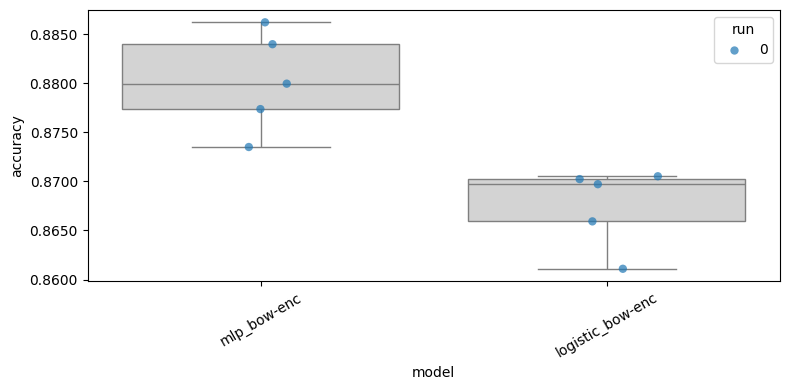

In [21]:
analysis.plot_box_and_points(analysis.make_data_frame(my_classifiers))

In [ ]:
import Project1.loglin as loglin
from sklearn.metrics import classification_report

def report_all_folds(seed=0, split="validation", num_folds=num_folds):
    X = np.vstack([token_indicator_encoder(s) for s in dataset[split]["sentence"]])  # encode once
    y_true = dataset[split]["label"]

    for fold in range(num_folds):
        path = f"Project1/results/logistic_indicator-enc/seed-{seed}/fold-{fold}/model"
        model = loglin.load(path)
        y_pred = model.predict(X)

        print(f"=== seed {seed}, fold {fold} ===")
        print(classification_report(y_true, y_pred,
                                    target_names=stanfordnlpsst2_outcome_space.names))

report_all_folds()

=== seed 0, fold 0 ===
              precision    recall  f1-score   support

    negative       0.71      0.70      0.70       428
    positive       0.71      0.72      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872

=== seed 0, fold 1 ===
              precision    recall  f1-score   support

    negative       0.71      0.69      0.70       428
    positive       0.71      0.73      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872

=== seed 0, fold 2 ===
              precision    recall  f1-score   support

    negative       0.71      0.71      0.71       428
    positive       0.72      0.72      0.72       444

    accuracy                           0.72       872
   macro avg       0.72      0.72      0.72       872
weigh

In [ ]:
import Project1.loglin as loglin
from sklearn.metrics import classification_report

path = 'Project1/results/logistic_indicator-enc/seed-0/fold-3/model'
model = loglin.load(path)

X = dataset['validation']['sentence']
X_tokanised = np.vstack([token_indicator_encoder(s) for s in X]) 
Y_pred = model.predict(X_tokanised)

print(classification_report(dataset["validation"]["label"], Y_pred, target_names=stanfordnlpsst2_outcome_space.names))

              precision    recall  f1-score   support

    negative       0.71      0.70      0.70       428
    positive       0.71      0.73      0.72       444

    accuracy                           0.71       872
   macro avg       0.71      0.71      0.71       872
weighted avg       0.71      0.71      0.71       872



???

A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)=nan P(Tie)=nan P(B wins)=nan Effect Size=nan


/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2162: RuntimeWarning: divide by zero encountered in divide
  x = np.asarray((x - loc)/scale, dtype=dtyp)
/home/taravd/UVA/MscAI/Y1/NLP1/P1/NLP/Project1/analysis.py:117: RuntimeWarning: invalid value encountered in scalar divide
  return self.mean_diff / self.std
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2337: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
/home/taravd/miniconda3/envs/nlp1/lib/python3.14/site-packages/scipy/stats/_distn_infrastructure.py:2338: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


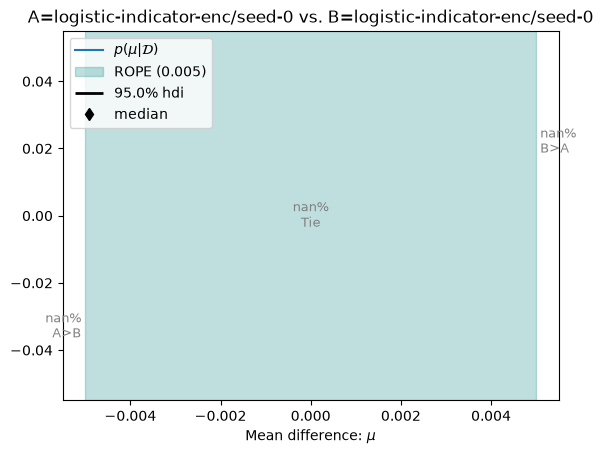

In [ ]:
# First, a little helper, to gather all accuracies across runs and folds
def get_all_measurements_for(data, sys_name):
    return np.array([list(run_data['accuracies'].values()) for run_data in data[sys_name]])

posterior = analysis.BenavoliCorrelatedT(
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    get_all_measurements_for(my_classifiers, 'logistic_indicator-enc').flatten(),  # this will have shape [num_runs * num_folds]
    names=["logistic-indicator-enc/seed-0", "logistic-indicator-enc/seed-0"]
)
p_a, p_tie, p_b = posterior.probs(0.005)
print(f"A=logistic_indicator-enc B=mlp_indicator-enc: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(0.005)  # if you need to zoom in or out reduce/increase the argument rope_factor (it doesn't affect the ROPE, only the visualisation of it)